# Research question. What structure exists in Fashion-MNIST, how can different machine-learning models exploit that structure, and what do their successes and failures teach us about the data and its representations?

## Part 0 - Setup: data and computing

### 0.1 Fixed Data Partitions

1. First load the data, 60,000 official train and 10,000 official test data. 
2. Then split the official training set, stratified and seeded: 50,000 train and 10,000 validation. 
    - Stratification means splitting or sampling data so that each resulting partition or subset preserves approx the same class proportions as the source data. Randomly select examples within each class
    - For example, if each of the ten classes represents 10% of the source data, a stratified 10,000 image subset contains approx 1,000 images per class. Use a fixed random seed and save the selected indices so that your splits are reproducible.
3. Save the seed and indices
4. CPU Friendly option, fit models on a fixed stratified 10,000 image subset of the training partition; keep the same validation and test sets. 

In [1]:
# Installations
%pip install scikit-learn
%pip install numpy
%pip install torchvision
%pip install pandas
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [40]:
#Imports
import numpy as np
import sklearn
from sklearn import model_selection
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib

#For FashionMNIST dataset
import torchvision
import torch
from torchvision.datasets import FashionMNIST

#Fixed seed
seed = 0

**1. Load the training data.**

In [3]:
#Make sure to have windows defender protection off
training_data = FashionMNIST(root="data", train=True, download=True)
testing_data = FashionMNIST(root="data", train=False, download=True)

#Get the data and labels from the dataset
x = training_data.data.numpy()
y = training_data.targets.numpy()

#Same for testing data (untouched until final eval)
x_test = testing_data.data.numpy()
y_test = testing_data.targets.numpy()



**2. Split the offficial training set. | 3. CPU-friendly option**
Must also save the indices of each 

In [4]:
#Create list of indices for subsets
indices = np.arange(len(y))

#50000 train and 10000 validation. Fixed seed for reproducibility. stratify = y ensures that the class distribution is proportional to the original dataset.
x_train, x_val, y_train, y_val, train_indices, val_indices = model_selection.train_test_split(x, y, indices, test_size=1/6, random_state=seed, stratify=y)

#CPU-friend option: stratified 10,000-image subset of the training parition for faster training.
x_train2, _, y_train2, _, train_indices2, _ = model_selection.train_test_split(x_train, y_train, train_indices, train_size = 0.2, random_state = seed, stratify=y_train)


**4. Cluster / Feature-extraction subset.**

In [5]:
#Create test indices for 1000 test images. 
test_indices = np.arange(len(y_test))

#Create fixed 3000 train, 1000 validation and 1000 test images
x_cluster_train, _, y_cluster_train, _, cluster_train_indices, _ = model_selection.train_test_split(x_train2, y_train2, train_indices2, train_size = 3000, random_state = seed, stratify=y_train2)
x_cluster_val, _, y_cluster_val, _, cluster_val_indices, _ = model_selection.train_test_split(x_val, y_val, val_indices, train_size = 1000, random_state = seed, stratify=y_val)
x_cluster_test, _, y_cluster_test, _, cluster_test_indices, _ = model_selection.train_test_split(x_test, y_test, test_indices, train_size = 1000, random_state = seed, stratify=y_test)

**5. Save the seed and indices.** (note: the order is not the same as on the brief due to restart and run all optimisation e.g. cluster subsets need to be made before saving the subsets into a file therefore some parts of 5 are done before 2)

In [6]:
#Save as numpy file 
np.savez(
    'splits/indices.npz',
    train_indices=train_indices, #50 000 training indices
    val_indices=val_indices, #10 000 validation indices
    subset_indices=train_indices2, #10 000 training subset indices
    seed=seed
)

#Save clustering indices
np.savez(
    'splits/clustering_indices.npz',
    train_indices=cluster_train_indices,
    val_indices=cluster_val_indices,
    test_indices=cluster_test_indices,
    seed=seed
)

In [7]:
#Check cluster and subset shapes
print(x_cluster_train.shape)
print(x_cluster_val.shape)
print(x_cluster_test.shape)
print(x_train.shape)
print(x_train2.shape)
print(x_val.shape)
print(x_test.shape)
print(y_train.shape)

(3000, 28, 28)
(1000, 28, 28)
(1000, 28, 28)
(50000, 28, 28)
(10000, 28, 28)
(10000, 28, 28)
(10000, 28, 28)
(50000,)


### 0.2 Where to run your code | My Computer Environment

On a jupyter notebook (ipynb file) on VScode on my personal computer

- Operating system: Windows 10 Pro
- CPU: AMD Ryzen 7 5800X — 8 cores, 16 threads
- RAM: 32 GB
- GPU: NVIDIA GeForce RTX 4060 Ti — 8 GB VRAM
```text
I am using the CPU-friendly option (10,000 image subset of the training partition) so GPU isn't necessary however, I still included it just in case.
I will record approximate training, extraction and inference times. 
Then cache extracted features instead of recomputing them.
```

### 0.3 Suggested Repository Layout

I follow the recommended suggested repository layour apart from the root folder name
```text
ecs708-fashion-mnist/
|-- README.md # install, data download, commands, hardware, runtimes
|-- requirements.txt # pinned versions
|-- configs/ # one config file per experiment ID
|-- splits/ # saved split and subset indices (+ seeds)
|-- src/ # data, models, training, evaluation, clustering code
|-- results/ # logs, metrics tables, experiment register
|-- figures/ # generated Notebook figures (+ script mapping)
`-- scripts/ # e.g. smoke_run.sh, make_figures.py
```

### Cell for Determining Requirements

In [41]:

print("numpy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("torch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)

numpy: 2.5.4
scikit-learn: 1.9.1
torch: 2.15.0+cpu
torchvision: 0.29.2+cpu
pandas: 3.1.1
matplotlib: 3.11.2


# Part 1 - Classical Classification [10 marks]

Guiding question: How do different classifiers use the same data, and what can their errors tell us?
## What you must do
**1.2 Metrics.** Notebook overall accuracy and a class-level view of performance, with enough information for readers to interpret any proportions.

**1.3 Error analysis.** Inspect a small set of correct and incorrect predictions. Discuss easy and hard classes.

**1.4 Complexity study.** Vary parameters that control model complexity and explain how model complexity affects generalization.

**1.5 Decisions and costs.** Define a binary decision problem of your own, derived from the ten classes. Using validation data, show how the decision threshold trades one error against the other.


### **1.1 Models.** Choose at least two classifiers or configurations from the methods taught in the module. Justify your choice for this data.


```text
Two classifiers: multinomial logistic regression and decision trees.
Since we are working with 10 classes, both classifiers need to be able to classify k > 2 classes (in which cases binary logistic regression wouldn't work).
Logistic regression and decision trees are both multiclass classifiers, so therefore they are viable for this data.
Further, logistic regression constructs linear boundaries and produces probabilities for each class whereas decision trees can construct non-linear boundaries, and classifies based on a sequence of questions which are two different methods of classifying. 
They also have two different approaches to dealing with complexity and overfitting, for example regularisation for logistic regression and maximum depth for the decision tree. 
Comparing these classifiers on the same data allows me to investigate how their different prediction methods and complexity controls affect training and validation performance.
```

In [9]:
# First flatten the images to 1D arrays (10,000, 28, 28) -> (10,000, 784)
x_flat_train = x_train2.reshape(x_train2.shape[0], -1) / 255.0
x_flat_val = x_val.reshape(x_val.shape[0], -1) / 255.0
x_flat_test = x_test.reshape(x_test.shape[0], -1) / 255.0

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from time import perf_counter

# Train a logistic regression model on the flatttened data

lr_model = LogisticRegression(solver='lbfgs', C=1.0, max_iter=1000)

start = perf_counter()
lr_model.fit(x_flat_train, y_train2)
print("Logistic RegressionTraining time:", perf_counter() - start, "seconds")

# Train a decision tree model on the flattened data
dt_model = DecisionTreeClassifier(max_depth = 10, random_state = seed)

start = perf_counter()
dt_model.fit(x_flat_train, y_train2)
print("Decision Tree Training time:", perf_counter() - start, "seconds")


Logistic RegressionTraining time: 11.404485000002751 seconds
Decision Tree Training time: 2.3260501000004297 seconds


```text
I had an initial error:

Training time: 169.56188710000424 seconds

c:\Users\Jin-Soo\AppData\Local\Programs\Python\Python315\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
n_iter_i = _check_optimize_result
```
>  essentially it could not converge within the max iteration as indicated (1000) fix: Preprocessing rescale all pixel brightness from 0-255 -> 0-1

```text
improvement: went from time limit reached / max iteration reached down to 6-7 seconds

### **1.2 Metrics.** Notebook overall accuracy and a class-level view of performance, with enough information for readers to interpret any proportions

#### First Logistic Regression

In [11]:
from sklearn.metrics import accuracy_score

#Use the trained model to predict the validation set and measure its overall accuracy (as well as time taken)

start = perf_counter()
lr_val_predictions = lr_model.predict(x_flat_val)
lr_prediction_time = perf_counter() - start

lr_val_accuracy = accuracy_score(y_val, lr_val_predictions)

print("Logistic Regression Validation accuracy:", lr_val_accuracy)
print("Logistic Regression Prediction time:", lr_prediction_time, "seconds")

Logistic Regression Validation accuracy: 0.8372
Logistic Regression Prediction time: 0.017441500000131782 seconds


In [12]:
#class level view of performance (precision score, recall and f1 score)
from sklearn.metrics import precision_score, recall_score, f1_score

lr_precision = precision_score(y_val, lr_val_predictions, average = None, zero_division = 0)
lr_recall = recall_score(y_val, lr_val_predictions, average = None, zero_division = 0)
lr_f1 = f1_score(y_val, lr_val_predictions, average = None, zero_division = 0)

#Tabulate the results 
lr_results = pd.DataFrame({
    "Class": training_data.classes,
    "Class Count (Validation Set)": np.bincount(y_val),
    "Precision": lr_precision,
    "Recall": lr_recall,
    "F1 Score": lr_f1
})

lr_results

,Class,Class Count (Validation Set),Precision,Recall,F1 Score
0,T-shirt/top,1000,0.786282,0.791,0.788634
1,Trouser,1000,0.961616,0.952,0.956784
2,Pullover,1000,0.716123,0.724,0.720040
3,Dress,1000,0.853683,0.846,0.849824
4,Coat,1000,0.719478,0.772,0.744814
5,Sandal,1000,0.907067,0.937,0.921790
6,Shirt,1000,0.619403,0.581,0.599587
7,Sneaker,1000,0.913669,0.889,0.901166
8,Bag,1000,0.954686,0.927,0.940639
9,Ankle boot,1000,0.939842,0.953,0.946375


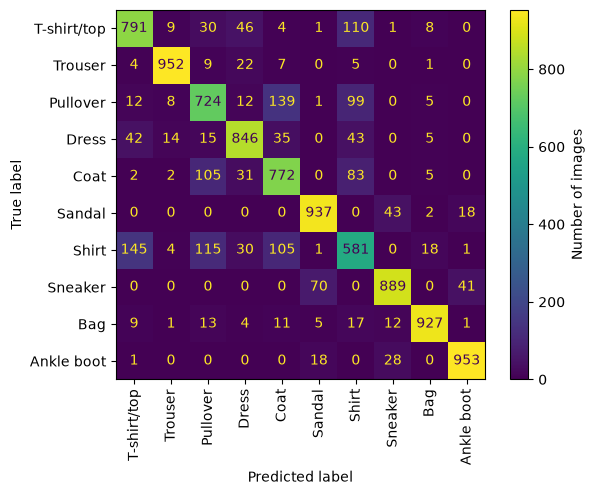

In [36]:
# Confusion Matrix for Logistic Regression
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

# Raw confusion matrix

lr_confusion_matrix = confusion_matrix(y_val, lr_val_predictions)
disp = ConfusionMatrixDisplay(confusion_matrix = lr_confusion_matrix, display_labels = training_data.classes)
disp.plot()

disp.im_.colorbar.set_label("Number of images")
plt.xticks(rotation=90)
plt.show()





#### Second Decision Trees

In [14]:
#Use the decision tree model to predict the validation set and measure its overall accuracy (as well as time taken)
start = perf_counter()    
dt_val_predictions = dt_model.predict(x_flat_val)
dt_prediction_time = perf_counter() - start

dt_val_accuracy = accuracy_score(y_val, dt_val_predictions)

print("Decision Tree Validation accuracy:", dt_val_accuracy)
print("Decision Tree Prediction time:", dt_prediction_time, "seconds")

Decision Tree Validation accuracy: 0.7827
Decision Tree Prediction time: 0.02701300000262563 seconds


In [15]:
# Class level view of performance (precision score, recall and f1 score)

dt_precision = precision_score(y_val, dt_val_predictions, average = None, zero_division = 0)
dt_recall = recall_score(y_val, dt_val_predictions, average = None, zero_division = 0)
dt_f1 = f1_score(y_val, dt_val_predictions, average = None, zero_division = 0)

#Tabulate the results
dt_results = pd.DataFrame({
    "Class": training_data.classes,
    "Class Count (Validation Set)": np.bincount(y_val),
    "Precision": dt_precision,
    "Recall": dt_recall,
    "F1 Score": dt_f1
})

dt_results

,Class,Class Count (Validation Set),Precision,Recall,F1 Score
0,T-shirt/top,1000,0.724539,0.747,0.735598
1,Trouser,1000,0.965373,0.920,0.942140
2,Pullover,1000,0.686848,0.658,0.672114
3,Dress,1000,0.762441,0.812,0.786441
4,Coat,1000,0.618785,0.784,0.691663
5,Sandal,1000,0.901587,0.852,0.876093
6,Shirt,1000,0.543590,0.424,0.476404
7,Sneaker,1000,0.857003,0.875,0.865908
8,Bag,1000,0.884694,0.867,0.875758
9,Ankle boot,1000,0.888000,0.888,0.888000


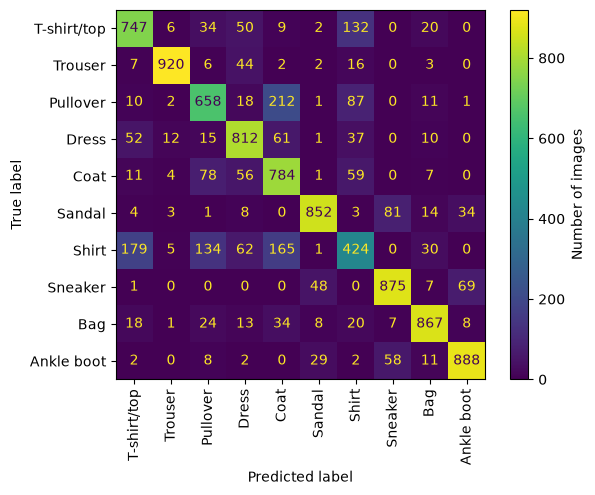

In [37]:
# Raw confusion matrix

dt_confusion_matrix = confusion_matrix(y_val, dt_val_predictions)
disp = ConfusionMatrixDisplay(confusion_matrix = dt_confusion_matrix, display_labels = training_data.classes)
disp.plot()

disp.im_.colorbar.set_label("Number of images")
plt.xticks(rotation=90)
plt.show()



### **1.3 Error Analysis.** Inspect a small set of correct and incorrect predictions. Discuss easy and hard classes

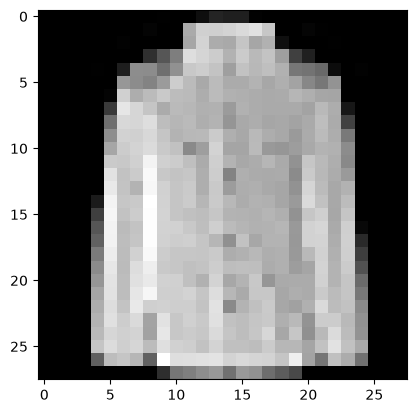

Actual: 4
Logistic regression: 4
Decision tree: 4


In [46]:
i = 2

plt.imshow(x_val[i], cmap='gray')
plt.show()

print("Actual:", y_val[i])
print("Logistic regression:", lr_val_predictions[i])
print("Decision tree:", dt_val_predictions[i])